# Análise Exploratória de Dados (EDA)

**Aluna:** Layse Steffany Pereira de Souza · UDF · Sistemas de Informação · Ciência de Dados e Aprendizado de Máquina (2026/2)

**Aula:** 26/08 · Unidade II – Análise e Ciência de Dados
**Atividade:** explorar um conjunto de dados, identificar padrões, valores ausentes e possíveis outliers.
**Entregável:** notebook/relatório de análise exploratória.

Base: características estáticas de arquivos executáveis (formato do EMBER), rotulados como
seguros (`label = 0`) ou maliciosos (`label = 1`). A análise é feita sobre a base **bruta**,
antes do tratamento, justamente para encontrar os problemas de qualidade.

In [1]:
import sys
from pathlib import Path

# Permite importar o pacote src/ a partir da pasta do notebook.
# No Google Colab, antes de rodar:
#   !git clone https://github.com/LaySteff/ciencia_dados_aprendizado_maquina.git
#   %cd ciencia_dados_aprendizado_maquina/unidade2_analise_e_ciencia_de_dados
RAIZ = Path.cwd().resolve().parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 30)
FIGURAS = RAIZ / "figuras"
FIGURAS.mkdir(exist_ok=True)

if config.usando_dados_sinteticos():
    print("AVISO: usando a base SINTÉTICA de demonstração. "
          "Os números abaixo são ilustrativos; refaça com a amostra real do EMBER.")
else:
    print("Usando a amostra real do EMBER.")

AVISO: usando a base SINTÉTICA de demonstração. Os números abaixo são ilustrativos; refaça com a amostra real do EMBER.


## 1. Visão geral da base

In [2]:
from src.preparacao import carregar_bruto

bruto = carregar_bruto()
print("Linhas, colunas:", bruto.shape)
bruto.head()

Linhas, colunas: (6150, 18)


,sha256,mes_aparicao,tamanho_bytes,num_secoes,entropia_media_secao,entropia_max_secao,num_importacoes,num_exportacoes,num_strings,entropia_strings,num_urls,num_paths,num_registro,possui_assinatura,possui_debug,possui_recursos,secao_exec_gravavel,label
0,77d83921b8077273000000000000000000000000000000...,2018-11,4197.0,4,4.4947,5.5865,118.0,0,1293.0,5.5455,4,4,0,0,0,1.0,0,0
1,7cc9c3a35ba409b5000000000000000000000000000000...,2018-05,1157473.0,5,4.9759,6.2030,NaN,14,730.0,5.4929,1,1,3,0,0,1.0,0,1
2,1c83bd40f2d026b7000000000000000000000000000000...,2018-12,252668.0,5,5.9036,6.3224,34.0,6,1171.0,5.4819,2,1,0,1,0,1.0,0,0
3,6009e80f65c8db78000000000000000000000000000000...,2018-02,67035.0,6,6.3451,7.2603,66.0,0,1374.0,6.0296,3,3,6,0,false,0.0,0,1
4,41335aeb170ebdca000000000000000000000000000000...,2018-09,40330.0,4,5.5441,6.2514,211.0,0,1801.0,4.9665,1,2,1,1,1,1.0,0,-1


In [3]:
bruto.dtypes.to_frame('tipo').T

,sha256,mes_aparicao,tamanho_bytes,num_secoes,entropia_media_secao,entropia_max_secao,num_importacoes,num_exportacoes,num_strings,entropia_strings,num_urls,num_paths,num_registro,possui_assinatura,possui_debug,possui_recursos,secao_exec_gravavel,label
tipo,str,str,float64,int64,float64,float64,float64,int64,float64,float64,int64,int64,int64,str,str,float64,int64,int64


## 2. Valores ausentes

In [4]:
ausentes = bruto.isna().sum()
ausentes = ausentes[ausentes > 0].sort_values(ascending=False)
pd.DataFrame({"ausentes": ausentes, "%": (ausentes / len(bruto) * 100).round(2)})

,ausentes,%
entropia_media_secao,187,3.04
num_importacoes,152,2.47
num_strings,122,1.98
possui_recursos,121,1.97
tamanho_bytes,60,0.98


## 3. Duplicatas, rótulos e formatos inconsistentes

In [5]:
print("Linhas duplicadas (exatas):", bruto.duplicated().sum())
print("sha256 com espaços/maiúsculas:", (bruto["sha256"] != bruto["sha256"].str.strip().str.lower()).sum())
print("\nDistribuição do rótulo (-1 = sem rótulo):")
print(bruto["label"].value_counts().sort_index())
print("\nValores distintos em possui_assinatura:", sorted(bruto["possui_assinatura"].astype(str).unique()))
print("Datas no formato MM/AAAA:", bruto["mes_aparicao"].str.contains("/").sum())

Linhas duplicadas (exatas): 150
sha256 com espaços/maiúsculas: 304

Distribuição do rótulo (-1 = sem rótulo):
label
-1     310
 0    3129
 1    2711
Name: count, dtype: int64

Valores distintos em possui_assinatura: ['0', '1', 'N', 'S', 'Sim', 'false', 'nao', 'não', 'sim', 'true']
Datas no formato MM/AAAA: 489


## 4. Estatísticas descritivas e valores inválidos

In [6]:
num = bruto[config.COLUNAS_NUMERICAS].apply(pd.to_numeric, errors="coerce")
num.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
tamanho_bytes,6090.0,850219.09,2013767.68,-1.00,117757.25,300025.50,744817.75,43490136.00
num_secoes,6150.0,5.84,2.25,1.00,4.00,6.00,7.00,15.00
entropia_media_secao,5963.0,5.66,1.02,2.11,4.92,5.60,6.42,7.95
entropia_max_secao,6150.0,6.46,1.08,3.01,5.70,6.44,7.29,11.85
num_importacoes,5998.0,92.40,62.18,1.00,44.00,85.00,127.75,443.00
num_exportacoes,6150.0,2.80,5.34,0.00,0.00,0.00,0.00,24.00
num_strings,6028.0,1367.83,1034.40,72.00,697.00,1109.00,1731.00,12215.00
entropia_strings,6150.0,5.68,0.51,3.86,5.33,5.68,6.03,7.69
num_urls,6150.0,1.89,1.43,0.00,1.00,2.00,3.00,9.00
num_paths,6150.0,3.08,1.80,0.00,2.00,3.00,4.00,12.00


In [7]:
print("Entropia máxima > 8 (impossível para entropia por byte):", (num["entropia_max_secao"] > 8).sum())
print("Tamanho <= 0 bytes:", (num["tamanho_bytes"] <= 0).sum())

Entropia máxima > 8 (impossível para entropia por byte): 32
Tamanho <= 0 bytes: 18


## 5. Outliers (critério IQR)

In [8]:
def contar_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

pd.Series({c: contar_outliers(num[c].dropna()) for c in num}, name="outliers").sort_values(ascending=False).to_frame()

,outliers
num_exportacoes,1431
tamanho_bytes,675
num_strings,290
num_importacoes,106
num_paths,98
num_secoes,79
num_registro,64
entropia_strings,29
entropia_max_secao,26
num_urls,26


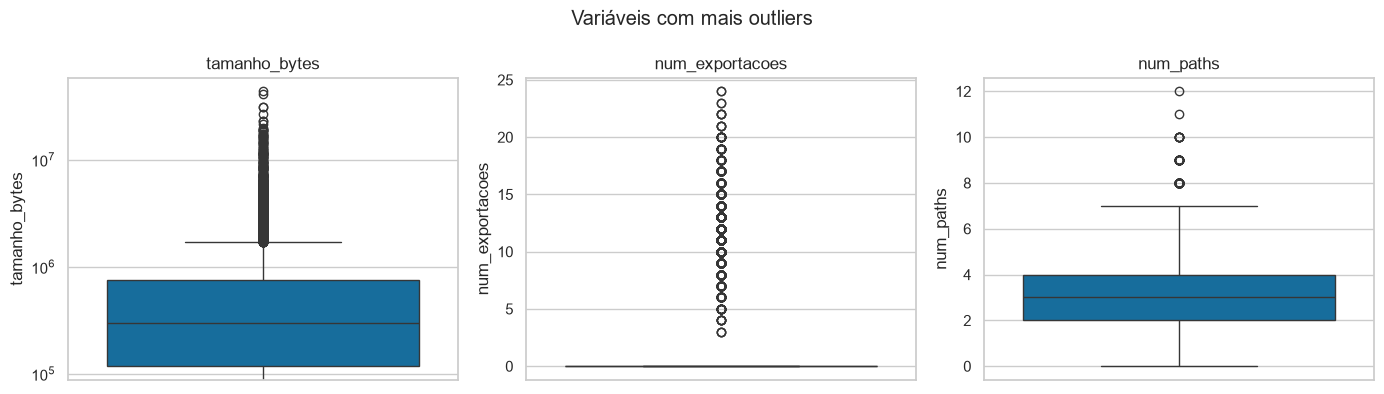

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["tamanho_bytes", "num_exportacoes", "num_paths"]):
    sns.boxplot(y=num[col], ax=ax)
    ax.set_title(col)
axes[0].set_yscale("log")
plt.suptitle("Variáveis com mais outliers")
plt.tight_layout(); plt.show()

## 6. Padrões: comparação entre arquivos seguros e maliciosos

In [10]:
rotulados = bruto[bruto["label"].isin([0, 1])].copy()
rotulados[config.COLUNAS_NUMERICAS] = rotulados[config.COLUNAS_NUMERICAS].apply(pd.to_numeric, errors="coerce")
rotulados.groupby("label")[config.COLUNAS_NUMERICAS].median().T.rename(columns={0: "seguro", 1: "malicioso"}).round(2)

label,seguro,malicioso
tamanho_bytes,397157.00,230377.50
num_secoes,6.00,6.00
entropia_media_secao,5.31,6.16
entropia_max_secao,6.12,6.98
num_importacoes,105.00,56.00
num_exportacoes,0.00,0.00
num_strings,1317.50,860.50
entropia_strings,5.51,5.89
num_urls,1.00,2.00
num_paths,3.00,3.00


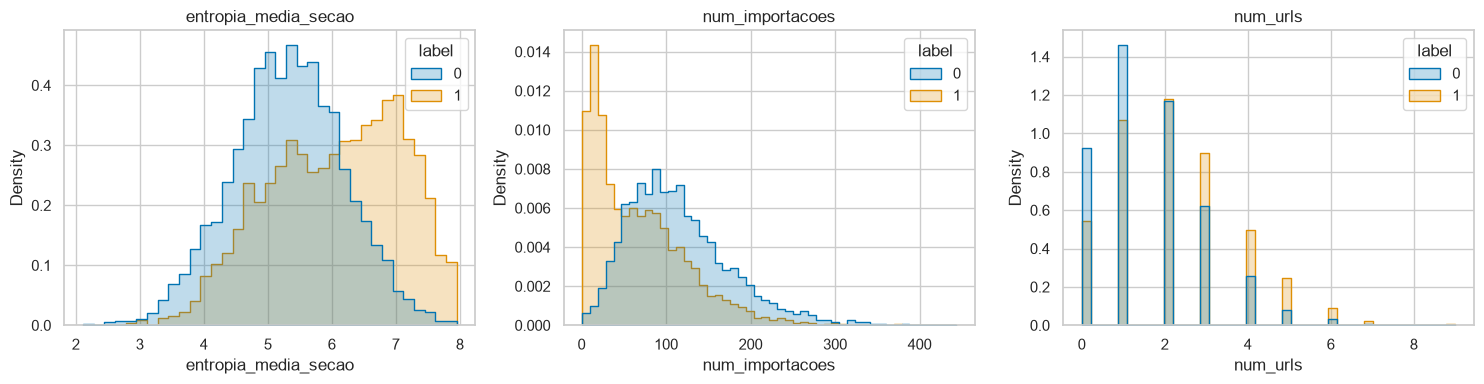

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["entropia_media_secao", "num_importacoes", "num_urls"]):
    sns.histplot(data=rotulados, x=col, hue="label", stat="density", common_norm=False,
                 element="step", ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

In [12]:
corr = rotulados[config.COLUNAS_NUMERICAS + ["label"]].corr(method="spearman")
corr["label"].drop("label").sort_values(key=abs, ascending=False).round(3).to_frame("correlação com label")

,correlação com label
num_importacoes,-0.404
entropia_strings,0.360
entropia_media_secao,0.357
entropia_max_secao,0.326
num_strings,-0.301
num_registro,0.253
num_urls,0.207
tamanho_bytes,-0.180
num_paths,-0.151
num_exportacoes,-0.151


## 7. Conclusões da EDA

> ⚠️ Valores obtidos com a base **sintética** de demonstração. Refaça a interpretação após rodar com a amostra real do EMBER.

**Problemas de qualidade encontrados (tratados na Unidade V):**

| Problema | Ocorrências | Tratamento previsto |
|---|---|---|
| Linhas duplicadas | 150 | remover |
| `sha256` com espaços/maiúsculas | ~300 | padronizar (e então checar duplicatas de novo) |
| Amostras sem rótulo (`label = -1`) | ~310 | remover (não servem para treino supervisionado) |
| Booleanos em texto (`sim`, `N`, `true`…) | ~10% de `possui_assinatura` e `possui_debug` | mapear para 0/1 |
| Datas em `MM/AAAA` | 489 | converter para `AAAA-MM` |
| Valores ausentes | 5 colunas, até ~3% cada | imputar (mediana / moda) |
| Entropia > 8 e tamanho ≤ 0 | 32 e 18 | impossíveis → tratar como ausentes |

**Padrões:**
- Os arquivos maliciosos têm **mediana de entropia maior** (≈ 6,2 contra 5,3) e **menos funções importadas** (≈ 56 contra 105). Isso é coerente com malwares compactados ou ofuscados, que escondem o código e importam poucas funções (hipótese H1).
- `num_importacoes`, as três entropias e `num_strings` são as variáveis mais correlacionadas com o rótulo (|ρ| entre 0,30 e 0,40). **Nenhuma variável separa as classes sozinha**, então um modelo precisa combinar várias.
- `tamanho_bytes` é muito assimétrico (vai de KB a dezenas de MB), por isso vale usar escala logarítmica.
- `num_exportacoes` tem muitos "outliers" pelo critério IQR só porque a maioria dos arquivos não exporta nada (mediana 0). Esses valores são legítimos e **não devem ser removidos**.